# Analisis Spasial Berbasis Machine Learning dengan Metode K-Means dalam Pemetaan Wilayah Prioritas Stunting di DKI Jakarta
tugas riset teknologi  informatika
m.rayhan
reza pahlehvi

---
**Data:** Tahun 2024  
**Metode:** K-Means Clustering (k=3)  
**Level Analisis:** Kelurahan · Kecamatan · Kota Administrasi  
**Variabel:**
- Jumlah Balita Pendek (Stunting) per Kelurahan/Kecamatan
- Persentase Akses Sanitasi Layak per Kota Administrasi
- Persentase Penduduk Miskin per Kota Administrasi

---
> **Folder Google Drive:** `stunting jakarta`  
> Pastikan semua file CSV sudah diunggah ke folder tersebut di Google Drive .

## 1. Mount Google Drive & Install Library

In [1]:
# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# Install library tambahan (jika belum tersedia)
!pip install -q scikit-learn matplotlib seaborn pandas numpy openpyxl

KeyboardInterrupt: 

## 2. Import Library

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import warnings
import os

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
from sklearn.decomposition import PCA

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 50)
pd.set_option('display.float_format', lambda x: '%.2f' % x)

# Pengaturan visual
plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.family'] = 'DejaVu Sans'
COLORS = ['#E74C3C', '#F39C12', '#27AE60']   # Merah=Tinggi, Kuning=Sedang, Hijau=Rendah

print('Semua library berhasil diimport.')

Semua library berhasil diimport.


## 3. Definisi Path File

In [8]:
# ============================================================
# SESUAIKAN NAMA FOLDER JIKA BERBEDA
# ============================================================
DRIVE_FOLDER = '/content/drive/MyDrive/stunting jakarta'

PATH_KELURAHAN   = os.path.join(DRIVE_FOLDER, '/content/drive/MyDrive/stunting jakarta/ Kelurahan.csv')
PATH_KECAMATAN   = os.path.join(DRIVE_FOLDER, '/content/drive/MyDrive/stunting jakarta/ Kecamatan.csv')
PATH_sANITASI    = os.path.join(DRIVE_FOLDER, '/content/drive/MyDrive/stunting jakarta/sanitasi.csv')
PATH_KEMISKINAN  = os.path.join(DRIVE_FOLDER, '/content/drive/MyDrive/stunting jakarta/Jumlah dan Persentase Penduduk Miskin .csv')
OUTPUT_FOLDER    = os.path.join(DRIVE_FOLDER, 'output')

os.makedirs(OUTPUT_FOLDER, exist_ok=True)

# Verifikasi semua file tersedia
paths = {
    'Data Stunting Kelurahan': PATH_KELURAHAN,
    'Data Stunting Kecamatan': PATH_KECAMATAN,
    'Data Sanitasi'          : PATH_SANITASI,
    'Data Kemiskinan'        : PATH_KEMISKINAN,
}
for nama, path in paths.items():
    status = '✅' if os.path.exists(path) else '❌ TIDAK DITEMUKAN'
    print(f'{status}  {nama}: {path}')

✅  Data Stunting Kelurahan: /content/drive/MyDrive/stunting jakarta/ Kelurahan.csv
✅  Data Stunting Kecamatan: /content/drive/MyDrive/stunting jakarta/ Kecamatan.csv
❌ TIDAK DITEMUKAN  Data Sanitasi: /content/drive/MyDrive/stunting jakarta/ Sanitasi.csv
✅  Data Kemiskinan: /content/drive/MyDrive/stunting jakarta/Jumlah dan Persentase Penduduk Miskin .csv


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 4. Load & Eksplorasi Data

In [9]:
# ── 4.1 Data Stunting per Kelurahan ──────────────────────────────────
df_kel = pd.read_csv(PATH_KELURAHAN)
print('=== Data Stunting Kelurahan ===')
print(f'Shape: {df_kel.shape}')
print(f'Kolom: {list(df_kel.columns)}')
display(df_kel.head(5))

=== Data Stunting Kelurahan ===
Shape: (267, 4)
Kolom: ['periode_data', 'wilayah', 'kelurahan', 'jumlah_balita_pendek']


,periode_data,wilayah,kelurahan,jumlah_balita_pendek
0,2024,KOTA ADM. JAKARTA PUSAT,KEL. CEMPAKA PUTIH BARAT,37
1,2024,KOTA ADM. JAKARTA PUSAT,KEL. CEMPAKA PUTIH TIMUR,30
2,2024,KOTA ADM. JAKARTA PUSAT,KEL. RAWASARI,14
3,2024,KOTA ADM. JAKARTA PUSAT,KEL. CIDENG,16
4,2024,KOTA ADM. JAKARTA PUSAT,KEL. DURI PULO,60


In [10]:
# ── 4.2 Data Stunting per Kecamatan ──────────────────────────────────
df_kec = pd.read_csv(PATH_KECAMATAN)
print('=== Data Stunting Kecamatan ===')
print(f'Shape: {df_kec.shape}')
display(df_kec.head(5))

=== Data Stunting Kecamatan ===
Shape: (44, 4)


,periode_data,wilayah,kecamatan,jumlah_balita_pendek
0,2024,KOTA ADM. JAKARTA PUSAT,KEC. CEMPAKA PUTIH,81
1,2024,KOTA ADM. JAKARTA PUSAT,KEC. GAMBIR,133
2,2024,KOTA ADM. JAKARTA PUSAT,KEC. JOHAR BARU,81
3,2024,KOTA ADM. JAKARTA PUSAT,KEC. KEMAYORAN,307
4,2024,KOTA ADM. JAKARTA PUSAT,KEC. MENTENG,79


In [11]:
# ── 4.3 Data Sanitasi (per Kota Administrasi) ───────────────────────
df_san_raw = pd.read_csv(PATH_SANITASI)
print(' Data Sanitasi (raw) ')
display(df_san_raw)

FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/stunting jakarta/ Sanitasi.csv'

In [ ]:
# ── 4.4 Data Kemiskinan (per Kota Administrasi) ─────────────────────
df_mis_raw = pd.read_csv(PATH_KEMISKINAN)
print(' Data Kemiskinan (raw) ')
display(df_mis_raw)

=== Data Kemiskinan (raw) ===


,Kabupaten/Kota,Garis Kemiskinan - Maret (Rp),Garis Kemiskinan - September (Rp),Jumlah Penduduk Miskin - Maret (ribu) (Ribu),Jumlah Penduduk Miskin - September (ribu) (Ribu),Persentase Penduduk Miskin - Maret,Persentase Penduduk Miskin - September
0,Kepulauan Seribu,775909,...,3.49,...,13.03,...
1,Kota Jakarta Selatan,928278,...,70.60,...,3.03,...
2,Kota Jakarta Timur,697472,...,121.52,...,4.09,...
3,Kota Jakarta Pusat,818722,...,42.33,...,4.63,...
4,Kota Jakarta Barat,685071,...,106.48,...,3.94,...
5,Kota Jakarta Utara,712835,...,120.51,...,6.44,...
6,DKI Jakarta,825288,846085,464.93,449.07,4.30,4.14


## 5. Preprocessing & Pembersihan Data

In [ ]:
#  5.1 Bersihkan Data Sanitasi
# File sanitasi memiliki 2 baris header awal yang perlu dilewati
df_san = df_san_raw.copy()
df_san.columns = ['kota_raw', 'pct_sanitasi']

# Hapus baris header / NaN
df_san = df_san.dropna(subset=['kota_raw'])
df_san = df_san[~df_san['pct_sanitasi'].astype(str).str.contains('Persentase|2024', na=True)]
df_san = df_san[df_san['kota_raw'] != 'DKI Jakarta'].reset_index(drop=True)
df_san['pct_sanitasi'] = pd.to_numeric(df_san['pct_sanitasi'], errors='coerce')

# Normalisasi nama kota
san_map = {
    'Kep Seribu'     : 'KAB. ADM. KEP. SERIBU',
    'Jakarta Selatan': 'KOTA ADM. JAKARTA SELATAN',
    'Jakarta Timur'  : 'KOTA ADM. JAKARTA TIMUR',
    'Jakarta Pusat'  : 'KOTA ADM. JAKARTA PUSAT',
    'Jakarta Barat'  : 'KOTA ADM. JAKARTA BARAT',
    'Jakarta Utara'  : 'KOTA ADM. JAKARTA UTARA',
}
df_san['wilayah'] = df_san['kota_raw'].map(san_map)
df_san = df_san[['wilayah', 'pct_sanitasi']].dropna()

print(' Data Sanitasi setelah preprocessing:')
display(df_san)

✅ Data Sanitasi setelah preprocessing:


,wilayah,pct_sanitasi
0,KAB. ADM. KEP. SERIBU,89.10
1,KOTA ADM. JAKARTA SELATAN,92.61
2,KOTA ADM. JAKARTA TIMUR,97.15
3,KOTA ADM. JAKARTA PUSAT,90.30
4,KOTA ADM. JAKARTA BARAT,94.94
5,KOTA ADM. JAKARTA UTARA,91.39


In [ ]:
# ── 5.2 Bersihkan Data Kemiskinan ────────────────────────────────────
df_mis = df_mis_raw.copy()

# Pilih kolom: nama kota dan persentase penduduk miskin Maret
df_mis = df_mis[['Kabupaten/Kota', 'Persentase Penduduk Miskin - Maret']].copy()
df_mis.columns = ['kota_raw', 'pct_miskin']
df_mis['pct_miskin'] = pd.to_numeric(df_mis['pct_miskin'], errors='coerce')

# Hapus baris DKI Jakarta (agregat)
df_mis = df_mis[df_mis['kota_raw'] != 'DKI Jakarta'].reset_index(drop=True)

# Normalisasi nama kota
mis_map = {
    'Kepulauan Seribu'   : 'KAB. ADM. KEP. SERIBU',
    'Kota Jakarta Selatan': 'KOTA ADM. JAKARTA SELATAN',
    'Kota Jakarta Timur' : 'KOTA ADM. JAKARTA TIMUR',
    'Kota Jakarta Pusat' : 'KOTA ADM. JAKARTA PUSAT',
    'Kota Jakarta Barat' : 'KOTA ADM. JAKARTA BARAT',
    'Kota Jakarta Utara' : 'KOTA ADM. JAKARTA UTARA',
}
df_mis['wilayah'] = df_mis['kota_raw'].map(mis_map)
df_mis = df_mis[['wilayah', 'pct_miskin']].dropna()

print(' Data Kemiskinan setelah preprocessing:')
display(df_mis)

✅ Data Kemiskinan setelah preprocessing:


,wilayah,pct_miskin
0,KAB. ADM. KEP. SERIBU,13.03
1,KOTA ADM. JAKARTA SELATAN,3.03
2,KOTA ADM. JAKARTA TIMUR,4.09
3,KOTA ADM. JAKARTA PUSAT,4.63
4,KOTA ADM. JAKARTA BARAT,3.94
5,KOTA ADM. JAKARTA UTARA,6.44


In [ ]:
# ── 5.3 Bersihkan Data Stunting Kelurahan ────────────────────────────
df_kel = df_kel[df_kel['periode_data'] == 2024].copy()
df_kel['kota'] = df_kel['wilayah'].str.strip()
df_kel['kelurahan'] = df_kel['kelurahan'].str.strip()
df_kel['jumlah_balita_pendek'] = pd.to_numeric(df_kel['jumlah_balita_pendek'], errors='coerce').fillna(0)

print(f' Data Kelurahan: {len(df_kel)} baris, {df_kel["kota"].nunique()} kota administrasi')
display(df_kel.head(5))

✅ Data Kelurahan: 267 baris, 6 kota administrasi


,periode_data,wilayah,kelurahan,jumlah_balita_pendek,kota
0,2024,KOTA ADM. JAKARTA PUSAT,KEL. CEMPAKA PUTIH BARAT,37,KOTA ADM. JAKARTA PUSAT
1,2024,KOTA ADM. JAKARTA PUSAT,KEL. CEMPAKA PUTIH TIMUR,30,KOTA ADM. JAKARTA PUSAT
2,2024,KOTA ADM. JAKARTA PUSAT,KEL. RAWASARI,14,KOTA ADM. JAKARTA PUSAT
3,2024,KOTA ADM. JAKARTA PUSAT,KEL. CIDENG,16,KOTA ADM. JAKARTA PUSAT
4,2024,KOTA ADM. JAKARTA PUSAT,KEL. DURI PULO,60,KOTA ADM. JAKARTA PUSAT


In [ ]:
# ── 5.4 Bersihkan Data Stunting Kecamatan ────────────────────────────
df_kec = df_kec[df_kec['periode_data'] == 2024].copy()
df_kec['kota'] = df_kec['wilayah'].str.strip()
df_kec['kecamatan'] = df_kec['kecamatan'].str.strip()
df_kec['jumlah_balita_pendek'] = pd.to_numeric(df_kec['jumlah_balita_pendek'], errors='coerce').fillna(0)

print(f' Data Kecamatan: {len(df_kec)} baris, {df_kec["kota"].nunique()} kota administrasi')
display(df_kec.head(5))

✅ Data Kecamatan: 44 baris, 6 kota administrasi


,periode_data,wilayah,kecamatan,jumlah_balita_pendek,kota
0,2024,KOTA ADM. JAKARTA PUSAT,KEC. CEMPAKA PUTIH,81,KOTA ADM. JAKARTA PUSAT
1,2024,KOTA ADM. JAKARTA PUSAT,KEC. GAMBIR,133,KOTA ADM. JAKARTA PUSAT
2,2024,KOTA ADM. JAKARTA PUSAT,KEC. JOHAR BARU,81,KOTA ADM. JAKARTA PUSAT
3,2024,KOTA ADM. JAKARTA PUSAT,KEC. KEMAYORAN,307,KOTA ADM. JAKARTA PUSAT
4,2024,KOTA ADM. JAKARTA PUSAT,KEC. MENTENG,79,KOTA ADM. JAKARTA PUSAT


In [ ]:
# ── 5.5 Gabungkan semua variabel ke dalam satu dataframe ─────────────
# Sanitasi & kemiskinan tersedia di level kota → join ke kelurahan & kecamatan

# --- Kelurahan ---
df_kel_merged = df_kel.merge(df_san, left_on='kota', right_on='wilayah', how='left')
df_kel_merged = df_kel_merged.merge(df_mis, left_on='kota', right_on='wilayah', how='left')
df_kel_merged = df_kel_merged[['kota', 'kelurahan', 'jumlah_balita_pendek', 'pct_sanitasi', 'pct_miskin']]
df_kel_merged.columns = ['kota', 'kelurahan', 'stunting', 'sanitasi', 'kemiskinan']

# --- Kecamatan ---
df_kec_merged = df_kec.merge(df_san, left_on='kota', right_on='wilayah', how='left')
df_kec_merged = df_kec_merged.merge(df_mis, left_on='kota', right_on='wilayah', how='left')
df_kec_merged = df_kec_merged[['kota', 'kecamatan', 'jumlah_balita_pendek', 'pct_sanitasi', 'pct_miskin']]
df_kec_merged.columns = ['kota', 'kecamatan', 'stunting', 'sanitasi', 'kemiskinan']

# --- Kota Administrasi (agregat dari kecamatan) ---
df_kota = df_kec.groupby('kota')['jumlah_balita_pendek'].sum().reset_index()
df_kota.columns = ['kota', 'stunting']
df_kota = df_kota.merge(df_san, left_on='kota', right_on='wilayah', how='left')
df_kota = df_kota.merge(df_mis, left_on='kota', right_on='wilayah', how='left')
df_kota = df_kota[['kota', 'stunting', 'pct_sanitasi', 'pct_miskin']]
df_kota.columns = ['kota', 'stunting', 'sanitasi', 'kemiskinan']

print(' Data Kelurahan merged:')
display(df_kel_merged.head(5))
print(f'\n Data Kecamatan merged:')
display(df_kec_merged.head(5))
print(f'\n Data Kota Administrasi merged:')
display(df_kota)

✅ Data Kelurahan merged:


,kota,kelurahan,stunting,sanitasi,kemiskinan
0,KOTA ADM. JAKARTA PUSAT,KEL. CEMPAKA PUTIH BARAT,37,90.30,4.63
1,KOTA ADM. JAKARTA PUSAT,KEL. CEMPAKA PUTIH TIMUR,30,90.30,4.63
2,KOTA ADM. JAKARTA PUSAT,KEL. RAWASARI,14,90.30,4.63
3,KOTA ADM. JAKARTA PUSAT,KEL. CIDENG,16,90.30,4.63
4,KOTA ADM. JAKARTA PUSAT,KEL. DURI PULO,60,90.30,4.63



✅ Data Kecamatan merged:


,kota,kecamatan,stunting,sanitasi,kemiskinan
0,KOTA ADM. JAKARTA PUSAT,KEC. CEMPAKA PUTIH,81,90.30,4.63
1,KOTA ADM. JAKARTA PUSAT,KEC. GAMBIR,133,90.30,4.63
2,KOTA ADM. JAKARTA PUSAT,KEC. JOHAR BARU,81,90.30,4.63
3,KOTA ADM. JAKARTA PUSAT,KEC. KEMAYORAN,307,90.30,4.63
4,KOTA ADM. JAKARTA PUSAT,KEC. MENTENG,79,90.30,4.63



✅ Data Kota Administrasi merged:


,kota,stunting,sanitasi,kemiskinan
0,KAB. ADM. KEP. SERIBU,889,89.10,13.03
1,KOTA ADM. JAKARTA BARAT,1459,94.94,3.94
2,KOTA ADM. JAKARTA PUSAT,980,90.30,4.63
3,KOTA ADM. JAKARTA SELATAN,1801,92.61,3.03
4,KOTA ADM. JAKARTA TIMUR,1567,97.15,4.09
5,KOTA ADM. JAKARTA UTARA,977,91.39,6.44


In [ ]:
# ── 5.6 Cek Missing Values ───────────────────────────────────────────
print('--- Missing Values Kelurahan ---')
print(df_kel_merged.isnull().sum())
print('\n--- Missing Values Kecamatan ---')
print(df_kec_merged.isnull().sum())
print('\n--- Missing Values Kota ---')
print(df_kota.isnull().sum())

--- Missing Values Kelurahan ---
kota          0
kelurahan     0
stunting      0
sanitasi      0
kemiskinan    0
dtype: int64

--- Missing Values Kecamatan ---
kota          0
kecamatan     0
stunting      0
sanitasi      0
kemiskinan    0
dtype: int64

--- Missing Values Kota ---
kota          0
stunting      0
sanitasi      0
kemiskinan    0
dtype: int64


In [ ]:
# ── 5.7 Statistik Deskriptif ─────────────────────────────────────────
print('=== Statistik Deskriptif — Kelurahan ===')
display(df_kel_merged[['stunting', 'sanitasi', 'kemiskinan']].describe().round(2))

print('\n=== Statistik Deskriptif — Kecamatan ===')
display(df_kec_merged[['stunting', 'sanitasi', 'kemiskinan']].describe().round(2))

=== Statistik Deskriptif — Kelurahan ===


,stunting,sanitasi,kemiskinan
count,267.00,267.00,267.00
mean,28.74,93.62,4.36
std,56.91,2.55,1.64
min,0.00,89.10,3.03
25%,8.00,91.39,3.94
50%,15.00,92.61,4.09
75%,33.00,94.94,4.63
max,811.00,97.15,13.03



=== Statistik Deskriptif — Kecamatan ===


,stunting,sanitasi,kemiskinan
count,44.00,44.00,44.00
mean,174.39,93.32,4.65
std,130.17,2.66,2.12
min,0.00,89.10,3.03
25%,106.25,91.39,3.94
50%,157.50,92.61,4.09
75%,206.25,94.94,4.63
max,862.00,97.15,13.03


## 6. Eksplorasi Visual Data (EDA)

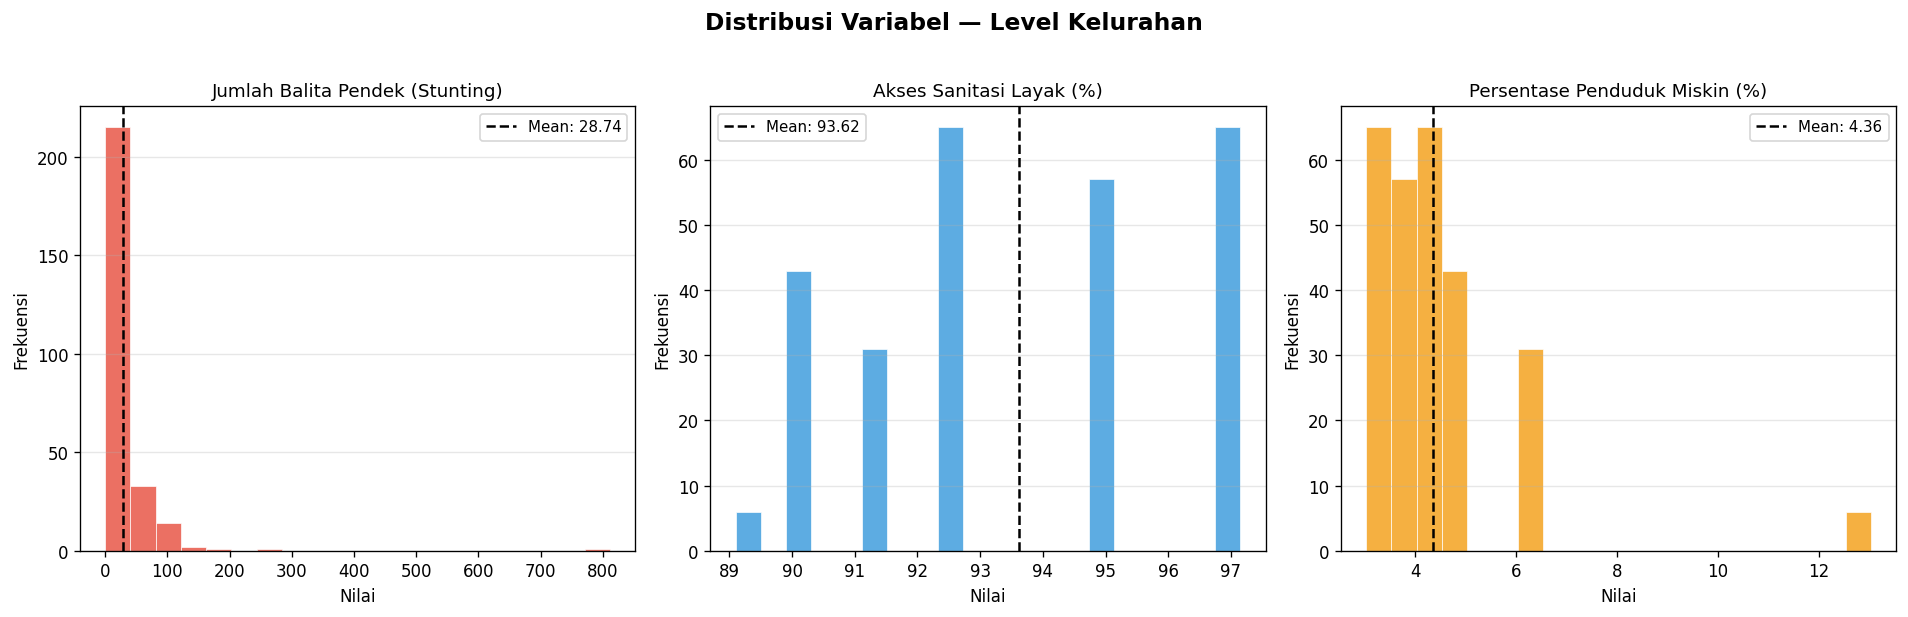

✅ Gambar disimpan: 01_distribusi_variabel.png


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle('Distribusi Variabel — Level Kelurahan', fontsize=14, fontweight='bold', y=1.02)

variabels = [
    ('stunting',   'Jumlah Balita Pendek (Stunting)', '#E74C3C'),
    ('sanitasi',   'Akses Sanitasi Layak (%)',         '#3498DB'),
    ('kemiskinan', 'Persentase Penduduk Miskin (%)',   '#F39C12'),
]

for ax, (col, label, color) in zip(axes, variabels):
    ax.hist(df_kel_merged[col].dropna(), bins=20, color=color, alpha=0.8, edgecolor='white', linewidth=0.5)
    ax.axvline(df_kel_merged[col].mean(), color='black', linestyle='--', linewidth=1.5, label=f'Mean: {df_kel_merged[col].mean():.2f}')
    ax.set_title(label, fontsize=11)
    ax.set_xlabel('Nilai')
    ax.set_ylabel('Frekuensi')
    ax.legend(fontsize=9)
    ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_FOLDER, '01_distribusi_variabel.png'), bbox_inches='tight', dpi=150)
plt.show()
print(' Gambar disimpan: 01_distribusi_variabel.png')

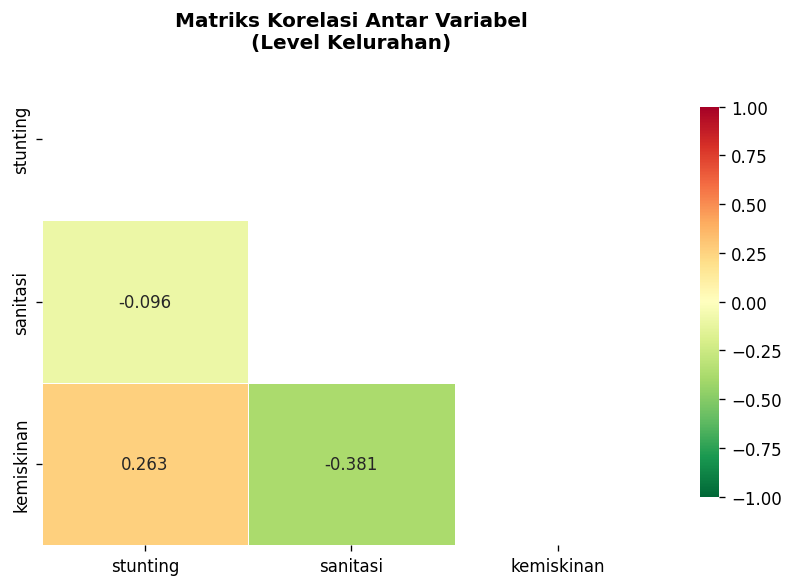

✅ Gambar disimpan: 02_korelasi.png


In [ ]:
# Korelasi antar variabel
fig, ax = plt.subplots(figsize=(7, 5))
corr = df_kel_merged[['stunting', 'sanitasi', 'kemiskinan']].corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, annot=True, fmt='.3f', cmap='RdYlGn_r',
            ax=ax, mask=mask, vmin=-1, vmax=1,
            linewidths=0.5, cbar_kws={'shrink': 0.8})
ax.set_title('Matriks Korelasi Antar Variabel\n(Level Kelurahan)', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_FOLDER, '02_korelasi.png'), bbox_inches='tight', dpi=150)
plt.show()
print(' Gambar disimpan: 02_korelasi.png')

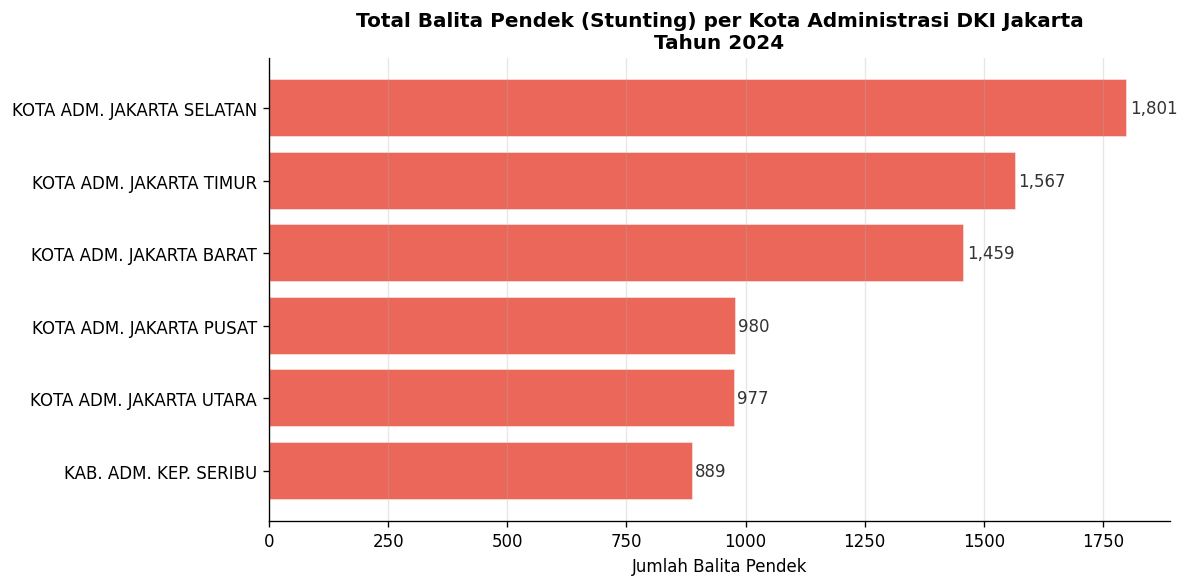

✅ Gambar disimpan: 03_stunting_per_kota.png


In [ ]:
# Stunting per Kota Administrasi
fig, ax = plt.subplots(figsize=(10, 5))
kota_plot = df_kota.sort_values('stunting', ascending=True)
bars = ax.barh(kota_plot['kota'], kota_plot['stunting'], color='#E74C3C', edgecolor='white', alpha=0.85)
for bar, val in zip(bars, kota_plot['stunting']):
    ax.text(bar.get_width() + 5, bar.get_y() + bar.get_height()/2,
            f'{int(val):,}', va='center', fontsize=10, color='#333')
ax.set_title('Total Balita Pendek (Stunting) per Kota Administrasi DKI Jakarta\nTahun 2024',
             fontsize=12, fontweight='bold')
ax.set_xlabel('Jumlah Balita Pendek')
ax.grid(axis='x', alpha=0.3)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_FOLDER, '03_stunting_per_kota.png'), bbox_inches='tight', dpi=150)
plt.show()
print(' Gambar disimpan: 03_stunting_per_kota.png')

## 7. Penentuan Jumlah Cluster Optimal (Elbow Method & Silhouette)

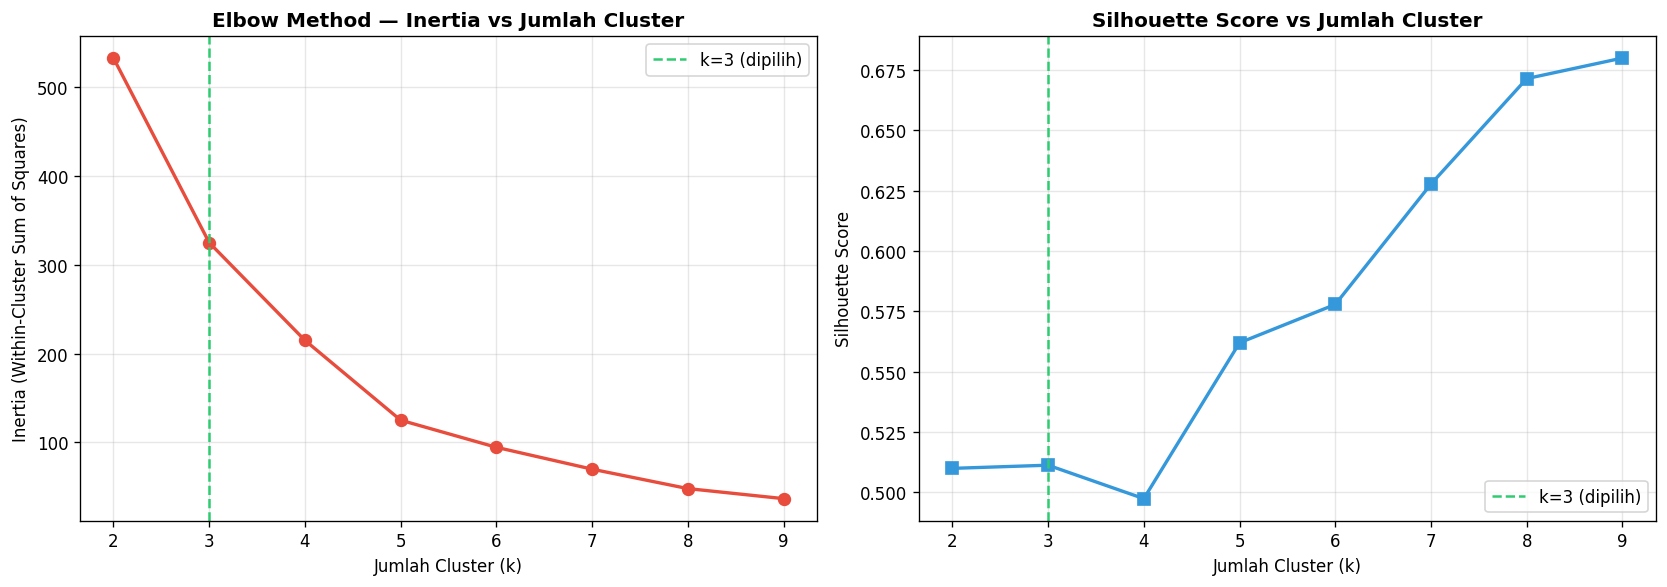

✅ Gambar disimpan: 04_elbow_silhouette.png

📊 Silhouette Score untuk k=3: 0.5112


In [ ]:
# Normalisasi fitur untuk Elbow Method (gunakan data kelurahan)
FEATURES = ['stunting', 'sanitasi', 'kemiskinan']

X_kel = df_kel_merged[FEATURES].dropna().values
scaler_elbow = StandardScaler()
X_kel_scaled = scaler_elbow.fit_transform(X_kel)

inertia   = []
sil_scores = []
K_range   = range(2, 10)

for k in K_range:
    km = KMeans(n_clusters=k, init='k-means++', n_init=20, random_state=42)
    km.fit(X_kel_scaled)
    inertia.append(km.inertia_)
    sil_scores.append(silhouette_score(X_kel_scaled, km.labels_))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Elbow
axes[0].plot(list(K_range), inertia, 'o-', color='#E74C3C', linewidth=2, markersize=7)
axes[0].axvline(x=3, color='#2ECC71', linestyle='--', linewidth=1.5, label='k=3 (dipilih)')
axes[0].set_title('Elbow Method — Inertia vs Jumlah Cluster', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Jumlah Cluster (k)')
axes[0].set_ylabel('Inertia (Within-Cluster Sum of Squares)')
axes[0].legend()
axes[0].grid(alpha=0.3)

# Silhouette
axes[1].plot(list(K_range), sil_scores, 's-', color='#3498DB', linewidth=2, markersize=7)
axes[1].axvline(x=3, color='#2ECC71', linestyle='--', linewidth=1.5, label='k=3 (dipilih)')
axes[1].set_title('Silhouette Score vs Jumlah Cluster', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Jumlah Cluster (k)')
axes[1].set_ylabel('Silhouette Score')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_FOLDER, '04_elbow_silhouette.png'), bbox_inches='tight', dpi=150)
plt.show()
print(f' Gambar disimpan: 04_elbow_silhouette.png')
print(f'\n📊 Silhouette Score untuk k=3: {sil_scores[1]:.4f}')

## 8. K-Means Clustering (k=3)

In [ ]:
# ── Fungsi utama clustering ──────────────────────────────────────────
def run_kmeans(df, id_col, feature_cols, k=3, random_state=42):
    """
    Menjalankan K-Means clustering dan mengembalikan dataframe dengan label cluster.
    Label cluster diurutkan berdasarkan nilai stunting (Cluster 1 = risiko tertinggi).
    """
    df_clean = df.dropna(subset=feature_cols).copy()

    # Normalisasi
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(df_clean[feature_cols])

    # K-Means
    km = KMeans(n_clusters=k, init='k-means++', n_init=30, max_iter=500, random_state=random_state)
    raw_labels = km.fit_predict(X_scaled)
    df_clean['_raw_cluster'] = raw_labels

    # Hitung rata-rata stunting per cluster → urutkan (tinggi=1, sedang=2, rendah=3)
    mean_stunt = df_clean.groupby('_raw_cluster')['stunting'].mean().sort_values(ascending=False)
    rank_map   = {orig: rank+1 for rank, orig in enumerate(mean_stunt.index)}
    df_clean['cluster'] = df_clean['_raw_cluster'].map(rank_map)
    df_clean.drop(columns=['_raw_cluster'], inplace=True)

    # Label keparahan
    label_map  = {1: 'Risiko Tinggi', 2: 'Risiko Sedang', 3: 'Risiko Rendah'}
    df_clean['keparahan'] = df_clean['cluster'].map(label_map)

    # Evaluasi
    sil  = silhouette_score(X_scaled, df_clean['cluster'])
    dbi  = davies_bouldin_score(X_scaled, df_clean['cluster'])
    chi  = calinski_harabasz_score(X_scaled, df_clean['cluster'])

    print(f'  Silhouette Score      : {sil:.4f}  (mendekati 1 = baik)')
    print(f'  Davies-Bouldin Score  : {dbi:.4f}  (mendekati 0 = baik)')
    print(f'  Calinski-Harabasz     : {chi:.2f}  (lebih tinggi = lebih baik)')

    return df_clean, {'silhouette': sil, 'davies_bouldin': dbi, 'calinski_harabasz': chi}

print(' Fungsi run_kmeans() siap digunakan.')

✅ Fungsi run_kmeans() siap digunakan.


In [ ]:
# ── 8.1 Clustering Level Kelurahan ───────────────────────────────────
print('=== K-Means Clustering — Level KELURAHAN ===')
df_kel_result, eval_kel = run_kmeans(
    df_kel_merged.copy(),
    id_col='kelurahan',
    feature_cols=['stunting', 'sanitasi', 'kemiskinan']
)
print(f'\nJumlah wilayah per cluster:')
print(df_kel_result.groupby(['cluster','keparahan'])['kelurahan'].count().rename('jumlah_kelurahan'))

=== K-Means Clustering — Level KELURAHAN ===
  Silhouette Score      : 0.5112  (mendekati 1 = baik)
  Davies-Bouldin Score  : 0.6132  (mendekati 0 = baik)
  Calinski-Harabasz     : 193.40  (lebih tinggi = lebih baik)

Jumlah wilayah per cluster:
cluster  keparahan    
1        Risiko Tinggi      1
2        Risiko Sedang    187
3        Risiko Rendah     79
Name: jumlah_kelurahan, dtype: int64


In [ ]:
# ── 8.2 Clustering Level Kecamatan ───────────────────────────────────
print('=== K-Means Clustering — Level KECAMATAN ===')
df_kec_result, eval_kec = run_kmeans(
    df_kec_merged.copy(),
    id_col='kecamatan',
    feature_cols=['stunting', 'sanitasi', 'kemiskinan']
)
print(f'\nJumlah wilayah per cluster:')
print(df_kec_result.groupby(['cluster','keparahan'])['kecamatan'].count().rename('jumlah_kecamatan'))

=== K-Means Clustering — Level KECAMATAN ===
  Silhouette Score      : 0.4503  (mendekati 1 = baik)
  Davies-Bouldin Score  : 0.6651  (mendekati 0 = baik)
  Calinski-Harabasz     : 38.17  (lebih tinggi = lebih baik)

Jumlah wilayah per cluster:
cluster  keparahan    
1        Risiko Tinggi     1
2        Risiko Sedang    28
3        Risiko Rendah    15
Name: jumlah_kecamatan, dtype: int64


In [ ]:
# ── 8.3 Clustering Level Kota Administrasi ───────────────────────────
print('=== K-Means Clustering — Level KOTA ADMINISTRASI ===')
# Kota hanya 6 baris — gunakan k=3 (valid jika n >= k*2, di sini 6 >= 6 borderline)
# Jika error, gunakan manual threshold berdasarkan stunting
try:
    df_kota_result, eval_kota = run_kmeans(
        df_kota.copy(),
        id_col='kota',
        feature_cols=['stunting', 'sanitasi', 'kemiskinan']
    )
except Exception as e:
    print(f'  K-Means untuk kota gagal: {e}')
    print('    → Menggunakan pengelompokan manual berdasarkan stunting...')
    df_kota_result = df_kota.copy()
    tertiles = df_kota_result['stunting'].quantile([1/3, 2/3])
    conditions = [
        df_kota_result['stunting'] >= tertiles[2/3],
        df_kota_result['stunting'] >= tertiles[1/3],
        df_kota_result['stunting'] <  tertiles[1/3],
    ]
    df_kota_result['cluster']   = np.select(conditions, [1, 2, 3])
    df_kota_result['keparahan'] = np.select(conditions,
        ['Risiko Tinggi', 'Risiko Sedang', 'Risiko Rendah'])
    eval_kota = {}

print(f'\nHasil clustering kota:')
display(df_kota_result[['kota','stunting','sanitasi','kemiskinan','cluster','keparahan']])

=== K-Means Clustering — Level KOTA ADMINISTRASI ===
  Silhouette Score      : 0.4732  (mendekati 1 = baik)
  Davies-Bouldin Score  : 0.3675  (mendekati 0 = baik)
  Calinski-Harabasz     : 11.00  (lebih tinggi = lebih baik)

Hasil clustering kota:


,kota,stunting,sanitasi,kemiskinan,cluster,keparahan
0,KAB. ADM. KEP. SERIBU,889,89.10,13.03,3,Risiko Rendah
1,KOTA ADM. JAKARTA BARAT,1459,94.94,3.94,1,Risiko Tinggi
2,KOTA ADM. JAKARTA PUSAT,980,90.30,4.63,2,Risiko Sedang
3,KOTA ADM. JAKARTA SELATAN,1801,92.61,3.03,1,Risiko Tinggi
4,KOTA ADM. JAKARTA TIMUR,1567,97.15,4.09,1,Risiko Tinggi
5,KOTA ADM. JAKARTA UTARA,977,91.39,6.44,2,Risiko Sedang


## 9. Visualisasi Hasil Clustering

In [ ]:
# ── Fungsi visualisasi scatter plot clustering ────────────────────────
def plot_cluster_scatter(df, name_col, title, filename):
    fig, axes = plt.subplots(1, 2, figsize=(15, 6))
    fig.suptitle(title, fontsize=13, fontweight='bold')

    label_map = {1: 'Risiko Tinggi', 2: 'Risiko Sedang', 3: 'Risiko Rendah'}
    palette   = {1: COLORS[0], 2: COLORS[1], 3: COLORS[2]}
    patches   = [mpatches.Patch(color=c, label=f'Cluster {k} — {label_map[k]}')
                 for k, c in palette.items()]

    # Plot 1: Stunting vs Kemiskinan
    for cl, color in palette.items():
        sub = df[df['cluster'] == cl]
        axes[0].scatter(sub['stunting'], sub['kemiskinan'],
                        c=color, alpha=0.75, s=60, edgecolors='white', linewidth=0.4, label=label_map[cl])
    axes[0].set_xlabel('Jumlah Balita Pendek (Stunting)', fontsize=11)
    axes[0].set_ylabel('Persentase Penduduk Miskin (%)', fontsize=11)
    axes[0].set_title('Stunting vs Kemiskinan', fontsize=11)
    axes[0].legend(handles=patches, fontsize=9)
    axes[0].grid(alpha=0.3)

    # Plot 2: Stunting vs Sanitasi
    for cl, color in palette.items():
        sub = df[df['cluster'] == cl]
        axes[1].scatter(sub['stunting'], sub['sanitasi'],
                        c=color, alpha=0.75, s=60, edgecolors='white', linewidth=0.4)
    axes[1].set_xlabel('Jumlah Balita Pendek (Stunting)', fontsize=11)
    axes[1].set_ylabel('Akses Sanitasi Layak (%)', fontsize=11)
    axes[1].set_title('Stunting vs Sanitasi', fontsize=11)
    axes[1].legend(handles=patches, fontsize=9)
    axes[1].grid(alpha=0.3)

    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_FOLDER, filename), bbox_inches='tight', dpi=150)
    plt.show()
    print(f' Gambar disimpan: {filename}')

print('Fungsi plot_cluster_scatter() siap.')

✅ Fungsi plot_cluster_scatter() siap.


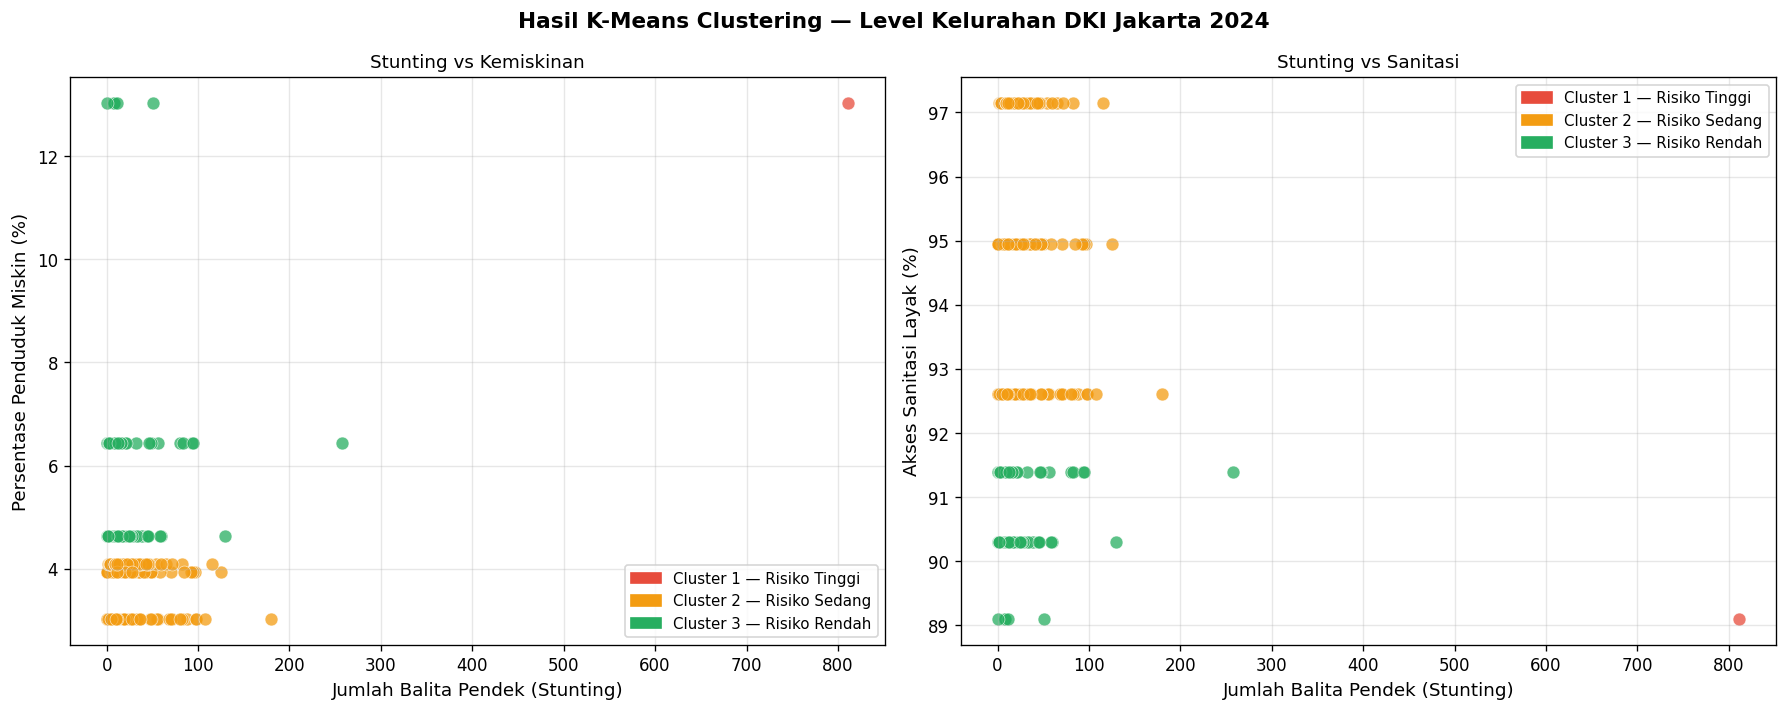

✅ Gambar disimpan: 05_scatter_kelurahan.png


In [ ]:
plot_cluster_scatter(
    df_kel_result, 'kelurahan',
    'Hasil K-Means Clustering — Level Kelurahan DKI Jakarta 2024',
    '05_scatter_kelurahan.png'
)

In [ ]:
plot_cluster_scatter(
    df_kec_result, 'kecamatan',
    'Hasil K-Means Clustering — Level Kecamatan DKI Jakarta 2024',
    '06_scatter_kecamatan.png'
)

In [ ]:
# ── Barplot distribusi cluster per kota (Kelurahan) ───────────────────
fig, ax = plt.subplots(figsize=(13, 6))

pivot = df_kel_result.groupby(['kota','keparahan']).size().unstack(fill_value=0)
# Urutkan kolom
for col in ['Risiko Tinggi', 'Risiko Sedang', 'Risiko Rendah']:
    if col not in pivot.columns:
        pivot[col] = 0
pivot = pivot[['Risiko Tinggi', 'Risiko Sedang', 'Risiko Rendah']]

pivot.plot(kind='bar', ax=ax, color=COLORS, edgecolor='white', linewidth=0.5, width=0.7)
ax.set_title('Distribusi Cluster Stunting per Kota Administrasi\n(Level Kelurahan, DKI Jakarta 2024)',
             fontsize=12, fontweight='bold')
ax.set_xlabel('')
ax.set_ylabel('Jumlah Kelurahan')
ax.legend(title='Tingkat Keparahan', fontsize=9)
ax.set_xticklabels(ax.get_xticklabels(), rotation=30, ha='right', fontsize=9)
ax.grid(axis='y', alpha=0.3)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_FOLDER, '07_distribusi_cluster_kota.png'), bbox_inches='tight', dpi=150)
plt.show()
print(' Gambar disimpan: 07_distribusi_cluster_kota.png')

In [ ]:
# ── Radar chart rata-rata variabel per cluster (Kelurahan) ────────────
from matplotlib.patches import FancyArrowPatch
import matplotlib.ticker as ticker

categories   = ['Stunting\n(Balita)', 'Sanitasi\n(%)', 'Kemiskinan\n(%)']
N            = len(categories)
angles       = [n / float(N) * 2 * np.pi for n in range(N)]
angles      += angles[:1]

cluster_labels = {1: 'Risiko Tinggi', 2: 'Risiko Sedang', 3: 'Risiko Rendah'}
means = {}
for cl in [1, 2, 3]:
    sub = df_kel_result[df_kel_result['cluster'] == cl]
    means[cl] = [sub['stunting'].mean(), sub['sanitasi'].mean(), sub['kemiskinan'].mean()]

# Normalisasi 0-1 untuk radar
all_vals = [v for vals in means.values() for v in vals]
vmin, vmax = min(all_vals), max(all_vals)
def norm01(x): return (x - vmin) / (vmax - vmin + 1e-9)

fig, ax = plt.subplots(figsize=(8, 8), subplot_kw=dict(polar=True))
ax.set_theta_offset(np.pi / 2)
ax.set_theta_direction(-1)
ax.set_xticks(angles[:-1])
ax.set_xticklabels(categories, fontsize=11)
ax.set_yticklabels([])

for cl, color in zip([1, 2, 3], COLORS):
    vals_norm = [norm01(v) for v in means[cl]] + [norm01(means[cl][0])]
    ax.plot(angles, vals_norm, 'o-', linewidth=2, color=color, label=f'Cluster {cl} — {cluster_labels[cl]}')
    ax.fill(angles, vals_norm, alpha=0.15, color=color)

ax.set_title('Profil Rata-rata Variabel per Cluster\n(Level Kelurahan, Ternormalisasi)',
             fontsize=12, fontweight='bold', pad=20)
ax.legend(loc='upper right', bbox_to_anchor=(1.35, 1.1), fontsize=9)

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_FOLDER, '08_radar_cluster.png'), bbox_inches='tight', dpi=150)
plt.show()
print(' Gambar disimpan: 08_radar_cluster.png')

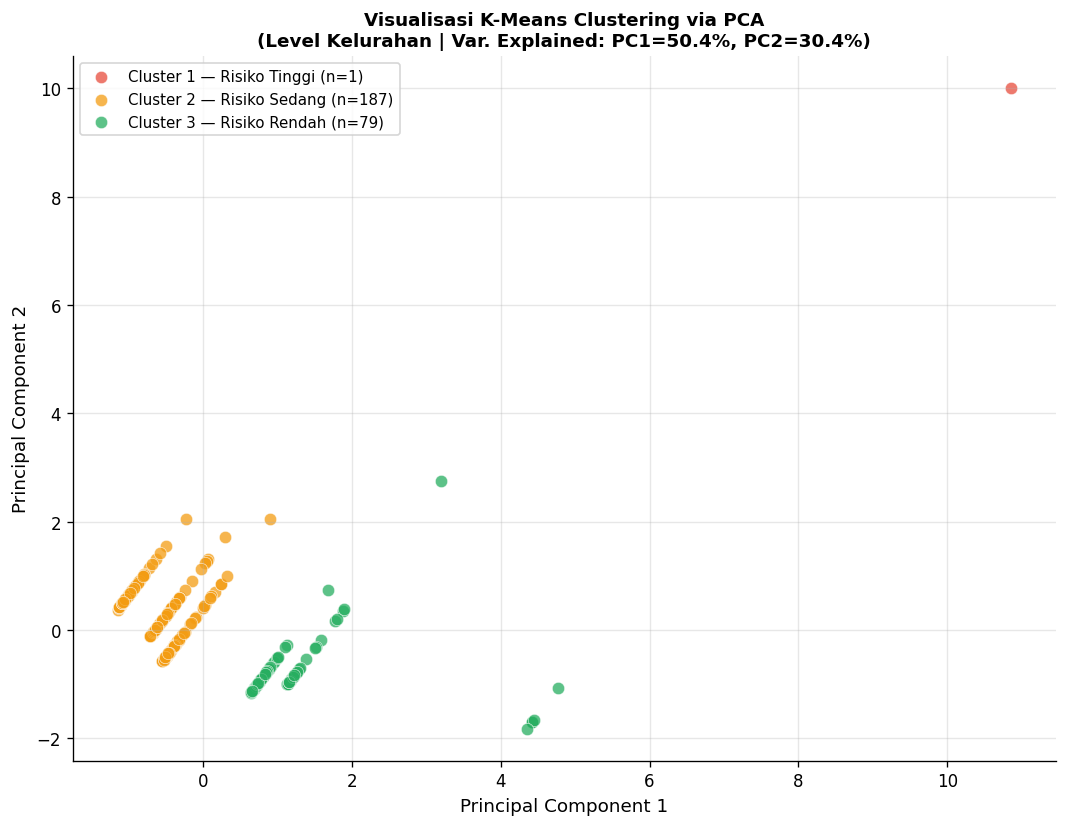

✅ Gambar disimpan: 09_pca_cluster.png


In [ ]:
# ── PCA 2D Visualization (Kelurahan) ─────────────────────────────────
X_pca_input = df_kel_result[['stunting','sanitasi','kemiskinan']].values
scaler_pca  = StandardScaler()
X_pca_scaled = scaler_pca.fit_transform(X_pca_input)
pca          = PCA(n_components=2, random_state=42)
X_pca        = pca.fit_transform(X_pca_scaled)

fig, ax = plt.subplots(figsize=(9, 7))
for cl, color in zip([1, 2, 3], COLORS):
    mask = df_kel_result['cluster'].values == cl
    ax.scatter(X_pca[mask, 0], X_pca[mask, 1],
               c=color, alpha=0.75, s=55, edgecolors='white', linewidth=0.4,
               label=f'Cluster {cl} — {cluster_labels[cl]} (n={mask.sum()})')

ax.set_title(
    f'Visualisasi K-Means Clustering via PCA\n'
    f'(Level Kelurahan | Var. Explained: PC1={pca.explained_variance_ratio_[0]*100:.1f}%, '
    f'PC2={pca.explained_variance_ratio_[1]*100:.1f}%)',
    fontsize=11, fontweight='bold')
ax.set_xlabel('Principal Component 1', fontsize=11)
ax.set_ylabel('Principal Component 2', fontsize=11)
ax.legend(fontsize=9)
ax.grid(alpha=0.3)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_FOLDER, '09_pca_cluster.png'), bbox_inches='tight', dpi=150)
plt.show()
print(' Gambar disimpan: 09_pca_cluster.png')

## 10. Ringkasan Hasil Clustering

In [ ]:
# ── 10.1 Ringkasan Kelurahan ──────────────────────────────────────────
print('\n' + '='*65)
print('  RINGKASAN HASIL CLUSTERING — LEVEL KELURAHAN')
print('='*65)
summary_kel = df_kel_result.groupby(['cluster','keparahan']).agg(
    jumlah_kelurahan=('kelurahan', 'count'),
    avg_stunting=('stunting', 'mean'),
    avg_sanitasi=('sanitasi', 'mean'),
    avg_kemiskinan=('kemiskinan', 'mean')
).round(2).reset_index()
display(summary_kel)

In [ ]:
# ── 10.2 Ringkasan Kecamatan ─────────────────────────────────────────
print('\n' + '='*65)
print('  RINGKASAN HASIL CLUSTERING — LEVEL KECAMATAN')
print('='*65)
summary_kec = df_kec_result.groupby(['cluster','keparahan']).agg(
    jumlah_kecamatan=('kecamatan', 'count'),
    avg_stunting=('stunting', 'mean'),
    avg_sanitasi=('sanitasi', 'mean'),
    avg_kemiskinan=('kemiskinan', 'mean')
).round(2).reset_index()
display(summary_kec)

In [ ]:
# ── 10.3 Detail Kelurahan Risiko Tinggi ──────────────────────────────
print('\n' + '='*65)
print('  KELURAHAN PRIORITAS — CLUSTER 1 (RISIKO TINGGI)')
print('='*65)
risiko_tinggi_kel = df_kel_result[df_kel_result['cluster'] == 1].sort_values('stunting', ascending=False)
display(risiko_tinggi_kel[['kota','kelurahan','stunting','sanitasi','kemiskinan','keparahan']].reset_index(drop=True))

In [ ]:
# ── 10.4 Detail Kecamatan Risiko Tinggi ──────────────────────────────
print('\n' + '='*65)
print('  KECAMATAN PRIORITAS — CLUSTER 1 (RISIKO TINGGI)')
print('='*65)
risiko_tinggi_kec = df_kec_result[df_kec_result['cluster'] == 1].sort_values('stunting', ascending=False)
display(risiko_tinggi_kec[['kota','kecamatan','stunting','sanitasi','kemiskinan','keparahan']].reset_index(drop=True))

In [ ]:
# ── 10.5 Hasil Kota Administrasi ─────────────────────────────────────
print('\n' + '='*65)
print('  HASIL CLUSTERING — LEVEL KOTA ADMINISTRASI')
print('='*65)
display(df_kota_result[['kota','stunting','sanitasi','kemiskinan','cluster','keparahan']].sort_values('cluster').reset_index(drop=True))

## 11. Evaluasi Model

In [ ]:
print('='*55)
print('  EVALUASI MODEL K-MEANS (k=3)')
print('='*55)
print(f"{'Level':<15} {'Silhouette':>14} {'Davies-Bouldin':>16} {'Calinski-Harabasz':>18}")
print('-'*55)
if eval_kel:
    print(f"{'Kelurahan':<15} {eval_kel['silhouette']:>14.4f} {eval_kel['davies_bouldin']:>16.4f} {eval_kel['calinski_harabasz']:>18.2f}")
if eval_kec:
    print(f"{'Kecamatan':<15} {eval_kec['silhouette']:>14.4f} {eval_kec['davies_bouldin']:>16.4f} {eval_kec['calinski_harabasz']:>18.2f}")
print('='*55)
print()
print('Interpretasi:')
print('  Silhouette Score  → mendekati 1.0 = cluster sangat terpisah baik')
print('  Davies-Bouldin    → mendekati 0.0 = cluster lebih kompak & terpisah')
print('  Calinski-Harabasz → semakin tinggi = cluster lebih terdefinisi baik')

## 12. Simpan Hasil ke Google Drive

In [ ]:
# Simpan semua hasil ke CSV
out_kel  = os.path.join(OUTPUT_FOLDER, 'hasil_clustering_kelurahan.csv')
out_kec  = os.path.join(OUTPUT_FOLDER, 'hasil_clustering_kecamatan.csv')
out_kota = os.path.join(OUTPUT_FOLDER, 'hasil_clustering_kota.csv')

df_kel_result[['kota','kelurahan','stunting','sanitasi','kemiskinan','cluster','keparahan']]\
    .sort_values(['cluster','kota','stunting'], ascending=[True,True,False])\
    .to_csv(out_kel, index=False)

df_kec_result[['kota','kecamatan','stunting','sanitasi','kemiskinan','cluster','keparahan']]\
    .sort_values(['cluster','kota','stunting'], ascending=[True,True,False])\
    .to_csv(out_kec, index=False)

df_kota_result[['kota','stunting','sanitasi','kemiskinan','cluster','keparahan']]\
    .sort_values('cluster')\
    .to_csv(out_kota, index=False)

print(' Semua file berhasil disimpan ke Google Drive:')
print(f'    {out_kel}')
print(f'    {out_kec}')
print(f'    {out_kota}')
print(f'    Gambar visualisasi → {OUTPUT_FOLDER}/')

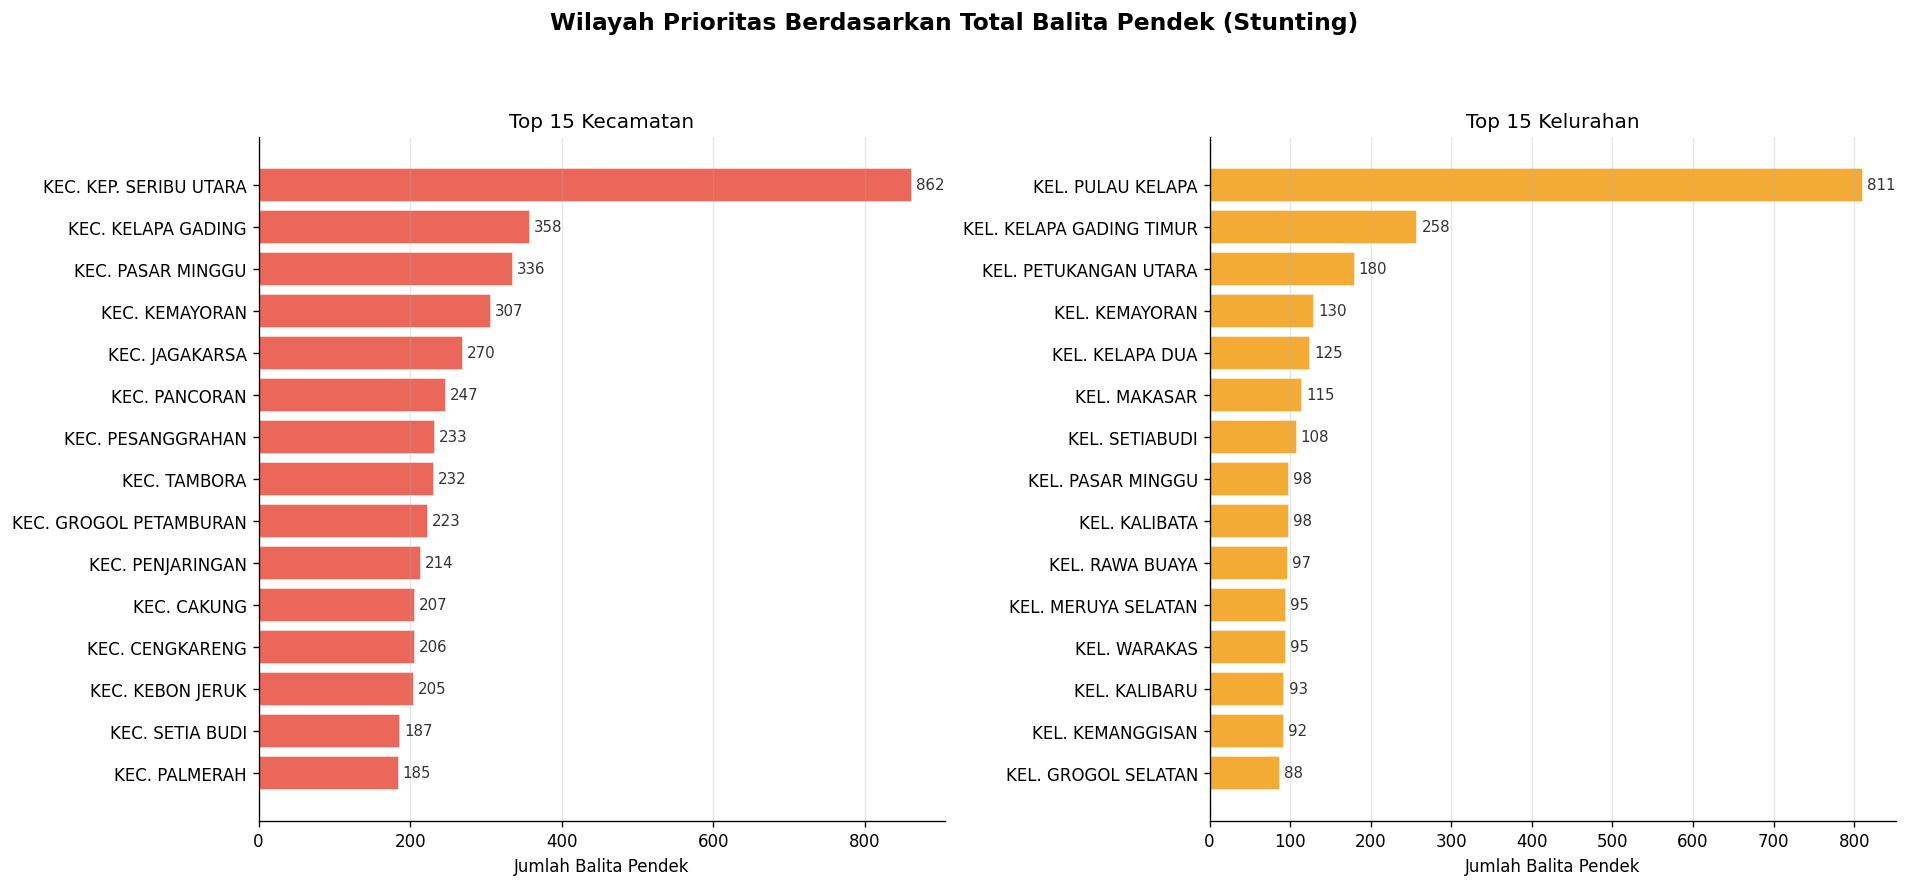

✅ Gambar disimpan: 10_top_stunting_wilayah.png


In [ ]:
# ── Visualisasi Top 15 Kecamatan & Kelurahan Tertinggi ────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
fig.suptitle('Wilayah Prioritas Berdasarkan Total Balita Pendek (Stunting)', fontsize=14, fontweight='bold', y=1.05)

# 1. Plot Top 15 Kecamatan
# Mengurutkan data dan mengambil 15 teratas, lalu di-reverse ([::-1]) agar bar tertinggi ada di paling atas
top_kec = df_kec_merged.sort_values('stunting', ascending=False).head(15)
bars_kec = axes[0].barh(top_kec['kecamatan'][::-1], top_kec['stunting'][::-1], color='#E74C3C', edgecolor='white', alpha=0.85)

axes[0].set_title('Top 15 Kecamatan', fontsize=12)
axes[0].set_xlabel('Jumlah Balita Pendek')
axes[0].grid(axis='x', alpha=0.3)
axes[0].spines['top'].set_visible(False)
axes[0].spines['right'].set_visible(False)

# Tambahkan label angka pada bar Kecamatan
for bar in bars_kec:
    axes[0].text(bar.get_width() + 5, bar.get_y() + bar.get_height()/2,
                 f'{int(bar.get_width()):,}', va='center', fontsize=9, color='#333')

# 2. Plot Top 15 Kelurahan
top_kel = df_kel_merged.sort_values('stunting', ascending=False).head(15)
bars_kel = axes[1].barh(top_kel['kelurahan'][::-1], top_kel['stunting'][::-1], color='#F39C12', edgecolor='white', alpha=0.85)

axes[1].set_title('Top 15 Kelurahan', fontsize=12)
axes[1].set_xlabel('Jumlah Balita Pendek')
axes[1].grid(axis='x', alpha=0.3)
axes[1].spines['top'].set_visible(False)
axes[1].spines['right'].set_visible(False)

# Tambahkan label angka pada bar Kelurahan
for bar in bars_kel:
    axes[1].text(bar.get_width() + 5, bar.get_y() + bar.get_height()/2,
                 f'{int(bar.get_width()):,}', va='center', fontsize=9, color='#333')

plt.tight_layout()

# Simpan output gambar ke Google Drive
path_gambar = os.path.join(OUTPUT_FOLDER, '10_top_stunting_wilayah.png')
plt.savefig(path_gambar, bbox_inches='tight', dpi=150)
plt.show()

print(f' Gambar disimpan: 10_top_stunting_wilayah.png')

---
## 13. FINAL OUTPUT — Visualisasi & Tabel Gabungan 3 Level
> Menampilkan hasil clustering **Kelurahan, Kecamatan, dan Kota Administrasi**
> dengan 3 variabel (Stunting · Sanitasi · Kemiskinan) secara lengkap dalam satu tampilan.

In [ ]:
# ═══════════════════════════════════════════════════════════════════
# FINAL OUTPUT — Visualisasi Gabungan 3 Variabel × 3 Level Wilayah
# ═══════════════════════════════════════════════════════════════════

import matplotlib.gridspec as gridspec
import matplotlib.ticker as mticker

COLORS_CLUSTER = {1: '#E74C3C', 2: '#F39C12', 3: '#27AE60'}
LABEL_CLUSTER  = {1: 'Cluster 1 — Risiko Tinggi',
                  2: 'Cluster 2 — Risiko Sedang',
                  3: 'Cluster 3 — Risiko Rendah'}

# ── BAGIAN 1: TABEL RINGKASAN GABUNGAN 3 LEVEL ──────────────────────
print('\n' + '═'*75)
print('  TABEL GABUNGAN — HASIL CLUSTERING K-MEANS (k=3) | DKI JAKARTA 2024')
print('═'*75)

def buat_ringkasan(df, level_col, level_name):
    tbl = df.groupby(['cluster','keparahan']).agg(
        jumlah=(level_col, 'count'),
        rata_stunting=('stunting', 'mean'),
        rata_sanitasi=('sanitasi', 'mean'),
        rata_kemiskinan=('kemiskinan', 'mean')
    ).round(2).reset_index()
    tbl.insert(0, 'Level', level_name)
    tbl.columns = ['Level','Cluster','Keparahan',f'Jumlah {level_name}',
                   'Rata-rata Stunting','Rata-rata Sanitasi (%)','Rata-rata Kemiskinan (%)']
    return tbl

tbl_kel  = buat_ringkasan(df_kel_result,  'kelurahan', 'Kelurahan')
tbl_kec  = buat_ringkasan(df_kec_result,  'kecamatan', 'Kecamatan')
tbl_kota = buat_ringkasan(df_kota_result, 'kota',      'Kota Admin')

# Gabung semua level
tbl_gabung = pd.concat([tbl_kel, tbl_kec, tbl_kota], ignore_index=True)
display(tbl_gabung)

# Simpan tabel gabungan
tbl_gabung.to_csv(os.path.join(OUTPUT_FOLDER, 'tabel_gabungan_3level.csv'), index=False)
print('\n✅ Tabel gabungan disimpan: tabel_gabungan_3level.csv')


# ── BAGIAN 2: FIGURE UTAMA — 3×3 GRID (3 Level × 3 Variabel) ────────
fig = plt.figure(figsize=(20, 18))
fig.suptitle(
    'Analisis Spasial K-Means Clustering — Wilayah Prioritas Stunting DKI Jakarta 2024\n'
    'Gabungan 3 Level: Kelurahan · Kecamatan · Kota Administrasi',
    fontsize=15, fontweight='bold', y=1.01
)

gs = gridspec.GridSpec(3, 3, figure=fig, hspace=0.45, wspace=0.35)

levels = [
    ('Kelurahan',         df_kel_result,  'kelurahan'),
    ('Kecamatan',         df_kec_result,  'kecamatan'),
    ('Kota Administrasi', df_kota_result, 'kota'),
]
variabel_pairs = [
    ('stunting',   'kemiskinan', 'Stunting (Balita)', 'Kemiskinan (%)'),
    ('stunting',   'sanitasi',   'Stunting (Balita)', 'Sanitasi (%)'),
    ('kemiskinan', 'sanitasi',   'Kemiskinan (%)',    'Sanitasi (%)'),
]

for row_i, (level_name, df_lvl, id_col) in enumerate(levels):
    for col_j, (x_col, y_col, x_label, y_label) in enumerate(variabel_pairs):
        ax = fig.add_subplot(gs[row_i, col_j])

        for cl in [1, 2, 3]:
            sub = df_lvl[df_lvl['cluster'] == cl]
            if len(sub) == 0:
                continue
            ax.scatter(
                sub[x_col], sub[y_col],
                c=COLORS_CLUSTER[cl],
                s=80 if level_name == 'Kota Administrasi' else 55,
                alpha=0.80, edgecolors='white', linewidth=0.5,
                label=LABEL_CLUSTER[cl], zorder=3
            )
            # Annotate nama kota (level kota saja)
            if level_name == 'Kota Administrasi':
                for _, r in sub.iterrows():
                    nama_pendek = r['kota'].replace('KOTA ADM. ','').replace('KAB. ADM. ','')
                    ax.annotate(nama_pendek,
                                (r[x_col], r[y_col]),
                                textcoords='offset points', xytext=(5, 4),
                                fontsize=7, color='#333')

        ax.set_xlabel(x_label, fontsize=9)
        ax.set_ylabel(y_label, fontsize=9)
        ax.set_title(f'{level_name}\n{x_label} vs {y_label}', fontsize=10, fontweight='bold')
        ax.grid(alpha=0.25, linestyle='--')
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.tick_params(labelsize=8)

        if row_i == 0 and col_j == 0:
            ax.legend(fontsize=7.5, loc='upper right', framealpha=0.8)

# Legend global di bawah
patches_legend = [mpatches.Patch(color=COLORS_CLUSTER[cl], label=LABEL_CLUSTER[cl]) for cl in [1,2,3]]
fig.legend(handles=patches_legend, loc='lower center', ncol=3,
           fontsize=11, frameon=True, bbox_to_anchor=(0.5, -0.02),
           title='Tingkat Keparahan Stunting', title_fontsize=11)

path_fig1 = os.path.join(OUTPUT_FOLDER, '11_final_scatter_3level_3variabel.png')
plt.savefig(path_fig1, bbox_inches='tight', dpi=150)
plt.show()
print(f'✅ Gambar disimpan: 11_final_scatter_3level_3variabel.png')


# ── BAGIAN 3: BARPLOT COMBINED — 3 VARIABEL PER CLUSTER PER LEVEL ───
fig2, axes2 = plt.subplots(1, 3, figsize=(20, 7))
fig2.suptitle(
    'Rata-rata 3 Variabel per Cluster — Perbandingan 3 Level Wilayah\nDKI Jakarta 2024',
    fontsize=14, fontweight='bold'
)

x_pos    = np.arange(3)   # 3 cluster
width    = 0.25
var_cols = ['stunting', 'sanitasi', 'kemiskinan']
var_label= ['Stunting (Balita)', 'Sanitasi (%)', 'Kemiskinan (%)']
var_colors = ['#E74C3C', '#3498DB', '#F39C12']

for ax_i, (level_name, df_lvl, _) in enumerate(levels):
    ax2 = axes2[ax_i]
    avgs = df_lvl.groupby('cluster')[var_cols].mean()

    for vi, (vcol, vlabel, vcolor) in enumerate(zip(var_cols, var_label, var_colors)):
        vals = [avgs.loc[cl, vcol] if cl in avgs.index else 0 for cl in [1,2,3]]
        bars = ax2.bar(x_pos + vi*width, vals, width,
                       label=vlabel, color=vcolor, alpha=0.85,
                       edgecolor='white', linewidth=0.5)
        for b in bars:
            ax2.text(b.get_x() + b.get_width()/2, b.get_height() + 0.5,
                     f'{b.get_height():.1f}', ha='center', va='bottom', fontsize=7.5, color='#333')

    ax2.set_title(f'Level {level_name}', fontsize=12, fontweight='bold')
    ax2.set_xticks(x_pos + width)
    ax2.set_xticklabels(['Cluster 1\nRisiko Tinggi','Cluster 2\nRisiko Sedang','Cluster 3\nRisiko Rendah'],
                        fontsize=9)
    ax2.set_ylabel('Nilai Rata-rata', fontsize=10)
    ax2.legend(fontsize=8.5, loc='upper right')
    ax2.grid(axis='y', alpha=0.3)
    ax2.spines['top'].set_visible(False)
    ax2.spines['right'].set_visible(False)

plt.tight_layout()
path_fig2 = os.path.join(OUTPUT_FOLDER, '12_final_barplot_3variabel_3level.png')
plt.savefig(path_fig2, bbox_inches='tight', dpi=150)
plt.show()
print(f'✅ Gambar disimpan: 12_final_barplot_3variabel_3level.png')


# ── BAGIAN 4: TABEL DETAIL SEMUA KELURAHAN (DENGAN WARNA) ────────────
print('\n' + '═'*75)
print('  DETAIL HASIL CLUSTERING — SEMUA KELURAHAN (Diurutkan per Cluster)')
print('═'*75)
detail_kel = df_kel_result[['kota','kelurahan','stunting','sanitasi','kemiskinan','cluster','keparahan']]\
    .sort_values(['cluster','stunting'], ascending=[True, False]).reset_index(drop=True)

def warnai_keparahan(val):
    if val == 'Risiko Tinggi': return 'background-color: #FADBD8; color: #922B21; font-weight:bold'
    elif val == 'Risiko Sedang': return 'background-color: #FDEBD0; color: #784212; font-weight:bold'
    else: return 'background-color: #D5F5E3; color: #1D6A39; font-weight:bold'

display(detail_kel.style.applymap(warnai_keparahan, subset=['keparahan']))

print('\n' + '═'*75)
print('  DETAIL HASIL CLUSTERING — SEMUA KECAMATAN')
print('═'*75)
detail_kec = df_kec_result[['kota','kecamatan','stunting','sanitasi','kemiskinan','cluster','keparahan']]\
    .sort_values(['cluster','stunting'], ascending=[True, False]).reset_index(drop=True)
display(detail_kec.style.applymap(warnai_keparahan, subset=['keparahan']))

print('\n' + '═'*75)
print('  DETAIL HASIL CLUSTERING — KOTA ADMINISTRASI')
print('═'*75)
detail_kota = df_kota_result[['kota','stunting','sanitasi','kemiskinan','cluster','keparahan']]\
    .sort_values(['cluster','stunting'], ascending=[True, False]).reset_index(drop=True)
display(detail_kota.style.applymap(warnai_keparahan, subset=['keparahan']))

print('\n✅ FINAL OUTPUT SELESAI — Semua visualisasi dan tabel tersimpan di folder output/')


---
## ✅ Selesai

| Output | Keterangan |
|---|---|
| `hasil_clustering_kelurahan.csv` | Hasil clustering 267 kelurahan dengan label keparahan |
| `hasil_clustering_kecamatan.csv` | Hasil clustering 44 kecamatan dengan label keparahan |
| `hasil_clustering_kota.csv` | Hasil clustering 6 kota administrasi |
| `tabel_gabungan_3level.csv` | **[BARU]** Tabel ringkasan gabungan 3 level sekaligus |
| `01_distribusi_variabel.png` | Histogram distribusi 3 variabel |
| `02_korelasi.png` | Matriks korelasi antar variabel |
| `03_stunting_per_kota.png` | Barplot stunting per kota admin |
| `04_elbow_silhouette.png` | Grafik Elbow & Silhouette Score |
| `05_scatter_kelurahan.png` | Scatter plot cluster level kelurahan |
| `06_scatter_kecamatan.png` | Scatter plot cluster level kecamatan |
| `07_distribusi_cluster_kota.png` | Distribusi cluster per kota administrasi |
| `08_radar_cluster.png` | Radar chart profil rata-rata per cluster |
| `09_pca_cluster.png` | Visualisasi PCA 2D cluster |
| `10_top_stunting_wilayah.png` | Top 15 kecamatan & kelurahan stunting tertinggi |
| `11_final_scatter_3level_3variabel.png` | **[BARU]** Grid 3×3 scatter plot gabungan semua level & variabel |
| `12_final_barplot_3variabel_3level.png` | **[BARU]** Barplot rata-rata 3 variabel per cluster × 3 level |

---
**Keterangan Cluster:**
- 🔴 **Cluster 1 — Risiko Tinggi**: Stunting tertinggi → prioritas intervensi utama
- 🟡 **Cluster 2 — Risiko Sedang**: Perlu pemantauan dan program pencegahan
- 🟢 **Cluster 3 — Risiko Rendah**: Kondisi stunting lebih terkendali

---
**Section 13 — FINAL OUTPUT menghasilkan:**
- Tabel gabungan 3 level (kelurahan, kecamatan, kota) dengan warna merah/kuning/hijau
- Figure 3×3: setiap baris = 1 level wilayah, setiap kolom = 1 pasangan variabel
- Barplot perbandingan rata-rata 3 variabel per cluster untuk ketiga level sekaligus
- Tabel detail seluruh kelurahan & kecamatan dengan highlight warna keparahan